
# 08 — Préparation du dataset historique (2023–2024)

## Objectif

Préparer les données historiques EnerVision pour entraîner et évaluer des modèles de prévision de consommation énergétique à horizons H+1 à H+24.

Ce notebook prolonge les analyses exploratoires réalisées dans `04_exploration_csv_data_part_1.ipynb` et `04_exploration_csv_data_part_2.ipynb`.

La préparation devra :

- Conserver la traçabilité des données sources.
- Identifier et traiter les anomalies sans masquer leur existence.
- Harmoniser les données avec le schéma utilisé dans nos précédentes expérimentations.
- Construire les variables historiques et calendaires disponibles au moment de la prévision.
- Éviter toute fuite de données entre entraînement, validation et test.
- Exporter un dataset supervisé réutilisable.

Les données d'origine resteront inchangées.

## A — Chargement et contrôles initiaux

Nous commençons par vérifier la structure, la période couverte, les sites présents et les valeurs manquantes avant toute transformation.


In [341]:
from pathlib import Path

import numpy as np
import pandas as pd

# Chemin à adapter à l'arborescence du projet
DATA_PATH = Path("../data/raw/all_sites_combined.csv")

df_raw = pd.read_csv(DATA_PATH)

# Analyse des horodatages, sans présumer du fuseau horaire
df_raw["timestamp"] = pd.to_datetime(df_raw["timestamp"], errors="coerce")

print("Dimensions :", df_raw.shape)
print("\nPériode couverte :")
print(df_raw["timestamp"].agg(["min", "max"]))

print("\nSites et catégories :")
print(
    df_raw.groupby(["site_id", "site_type"])
    .size()
    .rename("observations")
    .reset_index()
    .to_string(index=False)
)

print("\nValeurs manquantes :")
print(df_raw.isna().sum().sort_values(ascending=False).to_string())

print("\nDoublons site / timestamp :")
print(df_raw.duplicated(subset=["site_id", "timestamp"]).sum())

display(df_raw.head())

Dimensions : (122647, 15)

Période couverte :
min   2023-01-01
max   2024-12-31
Name: timestamp, dtype: datetime64[us]

Sites et catégories :
site_id  site_type  observations
SITE001     office         17521
SITE002    factory         17521
SITE003 datacenter         17521
SITE004     retail         17521
SITE005   hospital         17521
SITE006     office         17521
SITE007    factory         17521

Valeurs manquantes :
solar_irradiance_wm2    3964
humidity_percent        3423
temperature_celsius     3416
consumption_kwh         2840
consumption_euros       2487
site_type                  0
site_id                    0
site_name                  0
timestamp                  0
hour                       0
day_of_week                0
day_name                   0
month                      0
is_weekend                 0
is_working_hours           0

Doublons site / timestamp :
0


,timestamp,site_id,site_type,site_name,consumption_kwh,consumption_euros,temperature_celsius,humidity_percent,solar_irradiance_wm2,hour,day_of_week,day_name,month,is_weekend,is_working_hours
0,2023-01-01 00:00:00,SITE001,office,Bureau Tertiaire,85.82,12.87,10.6,76.7,0.0,0,6,Sunday,1,1,0
1,2023-01-01 01:00:00,SITE001,office,Bureau Tertiaire,89.84,13.48,12.0,70.6,0.0,1,6,Sunday,1,1,0
2,2023-01-01 02:00:00,SITE001,office,Bureau Tertiaire,80.62,12.09,13.8,62.2,0.0,2,6,Sunday,1,1,0
3,2023-01-01 03:00:00,SITE001,office,Bureau Tertiaire,92.67,13.90,9.4,66.0,0.0,3,6,Sunday,1,1,0
4,2023-01-01 04:00:00,SITE001,office,Bureau Tertiaire,72.50,10.88,14.8,67.2,41.5,4,6,Sunday,1,1,0



## B — Analyse des consommations manquantes et nulles

L'objectif est d'identifier la répartition des anomalies affectant la variable cible `consumption_kwh`.

Nous distinguons deux situations :

- Les valeurs manquantes (`NaN`), correspondant à une absence de mesure.
- Les valeurs nulles (`0`), pouvant représenter un arrêt réel de consommation ou une anomalie.

Nous étudions leur fréquence par site ainsi que la durée des interruptions consécutives afin de définir une stratégie de traitement adaptée.

À ce stade, aucune valeur n'est supprimée ou remplacée.


In [342]:
# B.1 — Répartition des consommations manquantes et nulles

df_quality = df_raw.copy()

df_quality = df_quality.sort_values(["site_id", "timestamp"])

df_quality["is_missing"] = df_quality["consumption_kwh"].isna()

df_quality["is_zero"] = df_quality["consumption_kwh"].eq(0)

# Synthèse par site
df_quality_by_site = (
    df_quality.groupby(["site_id", "site_type"])
    .agg(
        observations=("consumption_kwh", "size"),
        missing=("is_missing", "sum"),
        zero=("is_zero", "sum"),
    )
    .reset_index()
)

df_quality_by_site["missing_pct"] = (
    df_quality_by_site["missing"] / df_quality_by_site["observations"] * 100
).round(2)

df_quality_by_site["zero_pct"] = (
    df_quality_by_site["zero"] / df_quality_by_site["observations"] * 100
).round(2)

display(df_quality_by_site)


# Durée des séquences consécutives de valeurs manquantes
def missing_sequences(group):
    missing = group["is_missing"]

    sequence_id = missing.ne(missing.shift()).cumsum()

    return group.loc[missing].groupby(sequence_id[missing]).size()


sequences = []

for site_id, group in df_quality.groupby("site_id"):
    lengths = missing_sequences(group)

    sequences.append(
        {
            "site_id": site_id,
            "nb_interruptions": len(lengths),
            "max_duration_hours": lengths.max() if len(lengths) else 0,
            "mean_duration_hours": (round(lengths.mean(), 2) if len(lengths) else 0),
        }
    )

df_interruptions = pd.DataFrame(sequences)

display(df_interruptions)

,site_id,site_type,observations,missing,zero,missing_pct,zero_pct
0,SITE001,office,17521,411,281,2.35,1.60
1,SITE002,factory,17521,407,261,2.32,1.49
2,SITE003,datacenter,17521,407,235,2.32,1.34
3,SITE004,retail,17521,405,225,2.31,1.28
4,SITE005,hospital,17521,409,272,2.33,1.55
5,SITE006,office,17521,398,233,2.27,1.33
6,SITE007,factory,17521,403,285,2.30,1.63


,site_id,nb_interruptions,max_duration_hours,mean_duration_hours
0,SITE001,148,12,2.78
1,SITE002,156,11,2.61
2,SITE003,147,11,2.77
3,SITE004,143,8,2.83
4,SITE005,157,10,2.61
5,SITE006,147,8,2.71
6,SITE007,151,8,2.67



### B.2 — Analyse des consommations nulles

Les consommations égales à zéro peuvent correspondre à des arrêts d'activité, des défauts de mesure ou des anomalies introduites dans les données synthétiques.

Nous analysons leur répartition selon les types de bâtiments, les heures et les jours de la semaine afin de déterminer si elles correspondent à des comportements énergétiques plausibles.

Aucune correction n'est appliquée à ce stade.


In [343]:
# B.2 — Analyse des consommations nulles

df_zero = df_quality.loc[df_quality["is_zero"]].copy()

df_zero["hour"] = df_zero["timestamp"].dt.hour
df_zero["day_of_week"] = df_zero["timestamp"].dt.dayofweek

print("Consommations nulles par type de bâtiment :")
display(df_zero.groupby("site_type").size().rename("zero_count").reset_index())

print("Consommations nulles par heure :")
display(df_zero.groupby("hour").size().rename("zero_count").reset_index())

print("Consommations nulles par jour de semaine :")
display(df_zero.groupby("day_of_week").size().rename("zero_count").reset_index())

# Vérification de la consommation minimale positive
print("Consommations positives minimales par type :")
display(
    df_quality.loc[df_quality["consumption_kwh"] > 0]
    .groupby("site_type")["consumption_kwh"]
    .agg(["min", "median", "max"])
)

Consommations nulles par type de bâtiment :


,site_type,zero_count
0,datacenter,235
1,factory,546
2,hospital,272
3,office,514
4,retail,225


Consommations nulles par heure :


,hour,zero_count
0,0,69
1,1,66
2,2,60
3,3,69
4,4,81
5,5,76
6,6,81
7,7,73
8,8,73
9,9,78


Consommations nulles par jour de semaine :


,day_of_week,zero_count
0,0,231
1,1,204
2,2,269
3,3,278
4,4,296
5,5,245
6,6,269


Consommations positives minimales par type :


,min,median,max
site_type,,,
datacenter,147.89,828.460,2734.88
factory,43.82,486.710,4599.76
hospital,94.14,530.135,2471.61
office,7.41,87.100,1006.26
retail,17.14,215.980,1854.34



### B.3 — Stratégie de traitement des consommations invalides

L'analyse révèle une répartition relativement homogène des consommations nulles entre les sites, les heures et les jours de la semaine.

La présence de valeurs nulles dans des bâtiments à fonctionnement continu, notamment les datacenters et les hôpitaux, suggère qu'une partie de ces valeurs pourrait correspondre à des anomalies de mesure.

Pour cette expérimentation, nous retenons les règles suivantes :

- Les consommations manquantes sont considérées comme invalides.
- Les consommations nulles sont provisoirement considérées comme invalides.
- Les lignes correspondantes sont conservées afin de préserver la continuité temporelle.
- Aucune interpolation globale n'est appliquée.
- Les exemples supervisés dont la consommation cible est invalide seront exclus.
- Les variables historiques indisponibles seront traitées séparément, en respectant la chronologie des informations.

Ce choix constitue une hypothèse de nettoyage qui pourra être réévaluée à partir de la documentation du générateur de données.


In [344]:
# B.3 — Normalisation des consommations invalides

df_clean = df_raw.copy()

df_clean = df_clean.sort_values(["site_id", "timestamp"]).reset_index(drop=True)

# Conservation de l'information sur l'origine de l'anomalie
df_clean["consumption_was_missing"] = df_clean["consumption_kwh"].isna()

df_clean["consumption_was_zero"] = df_clean["consumption_kwh"].eq(0)

# Hypothèse : une consommation nulle est une mesure invalide
df_clean["consumption_kwh_clean"] = df_clean["consumption_kwh"].mask(
    df_clean["consumption_was_zero"]
)

print("Observations totales :", len(df_clean))

print("Consommations initialement manquantes :", df_clean["consumption_was_missing"].sum())

print("Consommations initialement nulles :", df_clean["consumption_was_zero"].sum())

print("Consommations valides après nettoyage :", df_clean["consumption_kwh_clean"].notna().sum())

print("Consommations invalides après nettoyage :", df_clean["consumption_kwh_clean"].isna().sum())

display(
    df_clean[
        [
            "site_id",
            "timestamp",
            "consumption_kwh",
            "consumption_kwh_clean",
            "consumption_was_missing",
            "consumption_was_zero",
        ]
    ].head(10)
)

Observations totales : 122647
Consommations initialement manquantes : 2840
Consommations initialement nulles : 1792
Consommations valides après nettoyage : 118015
Consommations invalides après nettoyage : 4632


,site_id,timestamp,consumption_kwh,consumption_kwh_clean,consumption_was_missing,consumption_was_zero
0,SITE001,2023-01-01 00:00:00,85.82,85.82,False,False
1,SITE001,2023-01-01 01:00:00,89.84,89.84,False,False
2,SITE001,2023-01-01 02:00:00,80.62,80.62,False,False
3,SITE001,2023-01-01 03:00:00,92.67,92.67,False,False
4,SITE001,2023-01-01 04:00:00,72.50,72.50,False,False
5,SITE001,2023-01-01 05:00:00,30.20,30.20,False,False
6,SITE001,2023-01-01 06:00:00,29.25,29.25,False,False
7,SITE001,2023-01-01 07:00:00,83.61,83.61,False,False
8,SITE001,2023-01-01 08:00:00,74.32,74.32,False,False
9,SITE001,2023-01-01 09:00:00,69.56,69.56,False,False



## C — Normalisation des données horaires

### C.1 — Vérification de la continuité temporelle

Avant de construire les variables prédictives, nous vérifions que chaque site dispose d'une série horaire continue.

Nous contrôlons également les éventuels écarts entre les informations calendaires présentes dans le CSV et celles calculées à partir des timestamps.

Les horodatages sont conservés dans leur fuseau d'origine, qui reste à confirmer. Aucune conversion UTC n'est appliquée à ce stade.


In [345]:
# C.1 — Contrôle de la continuité horaire

continuity_results = []

for site_id, group in df_clean.groupby("site_id"):
    timestamps = group["timestamp"].sort_values()

    differences = timestamps.diff().dropna()

    continuity_results.append(
        {
            "site_id": site_id,
            "observations": len(group),
            "hourly_intervals": differences.eq(pd.Timedelta(hours=1)).sum(),
            "non_hourly_intervals": differences.ne(pd.Timedelta(hours=1)).sum(),
            "min_timestamp": timestamps.min(),
            "max_timestamp": timestamps.max(),
        }
    )

df_continuity = pd.DataFrame(continuity_results)

display(df_continuity)

print("\nColonnes calendaires disponibles :")
print(
    [
        col
        for col in df_clean.columns
        if any(term in col.lower() for term in ["hour", "day", "week", "month", "holiday"])
    ]
)

,site_id,observations,hourly_intervals,non_hourly_intervals,min_timestamp,max_timestamp
0,SITE001,17521,17520,0,2023-01-01,2024-12-31
1,SITE002,17521,17520,0,2023-01-01,2024-12-31
2,SITE003,17521,17520,0,2023-01-01,2024-12-31
3,SITE004,17521,17520,0,2023-01-01,2024-12-31
4,SITE005,17521,17520,0,2023-01-01,2024-12-31
5,SITE006,17521,17520,0,2023-01-01,2024-12-31
6,SITE007,17521,17520,0,2023-01-01,2024-12-31



Colonnes calendaires disponibles :
['hour', 'day_of_week', 'day_name', 'month', 'is_weekend', 'is_working_hours']



### C.2 — Vérification des variables calendaires

Les variables calendaires constituent des caractéristiques importantes pour la prévision énergétique.

Nous vérifions leur cohérence avec les horodatages avant de décider de conserver les colonnes existantes ou de les recalculer.

Cette vérification porte notamment sur l'heure, le jour de la semaine, le mois et les indicateurs de week-end, lorsque ces informations sont disponibles.

Le fuseau horaire des données reste à confirmer.


In [346]:
# C.2 — Inspection des colonnes calendaires

calendar_columns = [
    col
    for col in df_clean.columns
    if any(term in col.lower() for term in ["hour", "day", "week", "month", "holiday"])
]

print("Colonnes calendaires disponibles :")
print(calendar_columns)

print("\nExemple des données calendaires :")

display(df_clean[["timestamp"] + calendar_columns].head(10))

print("\nValeurs distinctes par colonne :")

for col in calendar_columns:
    print(f"{col}:", df_clean[col].dropna().unique()[:15])

Colonnes calendaires disponibles :
['hour', 'day_of_week', 'day_name', 'month', 'is_weekend', 'is_working_hours']

Exemple des données calendaires :


,timestamp,hour,day_of_week,day_name,month,is_weekend,is_working_hours
0,2023-01-01 00:00:00,0,6,Sunday,1,1,0
1,2023-01-01 01:00:00,1,6,Sunday,1,1,0
2,2023-01-01 02:00:00,2,6,Sunday,1,1,0
3,2023-01-01 03:00:00,3,6,Sunday,1,1,0
4,2023-01-01 04:00:00,4,6,Sunday,1,1,0
5,2023-01-01 05:00:00,5,6,Sunday,1,1,0
6,2023-01-01 06:00:00,6,6,Sunday,1,1,0
7,2023-01-01 07:00:00,7,6,Sunday,1,1,0
8,2023-01-01 08:00:00,8,6,Sunday,1,1,1
9,2023-01-01 09:00:00,9,6,Sunday,1,1,1



Valeurs distinctes par colonne :
hour: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]
day_of_week: [6 0 1 2 3 4 5]
day_name: <ArrowStringArray>
['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
Length: 7, dtype: str
month: [ 1  2  3  4  5  6  7  8  9 10 11 12]
is_weekend: [1 0]
is_working_hours: [0 1]


Vérification de cohérence de variables calendaires

In [347]:
# C.2 — Vérification de cohérence des variables calendaires

calendar_checks = {
    "hour": df_clean["hour"].eq(df_clean["timestamp"].dt.hour),
    "day_of_week": df_clean["day_of_week"].eq(df_clean["timestamp"].dt.dayofweek),
    "month": df_clean["month"].eq(df_clean["timestamp"].dt.month),
    "is_weekend": df_clean["is_weekend"].eq(df_clean["timestamp"].dt.dayofweek.ge(5).astype(int)),
    "day_name": df_clean["day_name"].eq(df_clean["timestamp"].dt.day_name()),
}

df_calendar_checks = pd.DataFrame(
    {
        "variable": list(calendar_checks.keys()),
        "incoherences": [(~check).sum() for check in calendar_checks.values()],
    }
)

display(df_calendar_checks)

,variable,incoherences
0,hour,0
1,day_of_week,0
2,month,0
3,is_weekend,0
4,day_name,0



### C.3 — Construction du schéma horaire normalisé

Les contrôles précédents ont confirmé la continuité temporelle et la cohérence des variables calendaires.

Nous construisons désormais un jeu de données horaire normalisé destiné à alimenter notre pipeline de prévision.

Les règles retenues sont les suivantes :

- Une observation par site et par heure.
- Conservation des identifiants et catégories de sites.
- Utilisation des consommations nettoyées.
- Harmonisation de la consommation énergétique avec le schéma du précédent pipeline ML.
- Conservation des valeurs manquantes sans interpolation.
- Exclusion provisoire des variables météorologiques et économiques.

La conversion de `consumption_kwh` vers `consumption_kw` repose sur l'hypothèse que chaque valeur représente l'énergie consommée pendant une période d'une heure. Dans ce cas, la valeur numérique correspond à la puissance moyenne sur cette heure.

Le fuseau horaire reste à confirmer avant toute conversion UTC.


In [348]:
# C.3 — Création du dataset horaire normalisé

df_hourly = df_clean[
    [
        "site_id",
        "site_type",
        "timestamp",
        "consumption_kwh_clean",
        "hour",
        "day_of_week",
        "month",
        "is_weekend",
    ]
].copy()

# Conversion kWh sur une heure -> puissance moyenne en kW
df_hourly = df_hourly.rename(columns={"consumption_kwh_clean": "consumption_kw"})

df_hourly = df_hourly.sort_values(["site_id", "timestamp"]).reset_index(drop=True)

print("Dimensions :", df_hourly.shape)

print("\nValeurs manquantes :")
print(df_hourly.isna().sum())

print("\nTypes des colonnes :")
print(df_hourly.dtypes)

display(df_hourly.head())

Dimensions : (122647, 8)

Valeurs manquantes :
site_id              0
site_type            0
timestamp            0
consumption_kw    4632
hour                 0
day_of_week          0
month                0
is_weekend           0
dtype: int64

Types des colonnes :
site_id                      str
site_type                    str
timestamp         datetime64[us]
consumption_kw           float64
hour                       int64
day_of_week                int64
month                      int64
is_weekend                 int64
dtype: object


,site_id,site_type,timestamp,consumption_kw,hour,day_of_week,month,is_weekend
0,SITE001,office,2023-01-01 00:00:00,85.82,0,6,1,1
1,SITE001,office,2023-01-01 01:00:00,89.84,1,6,1,1
2,SITE001,office,2023-01-01 02:00:00,80.62,2,6,1,1
3,SITE001,office,2023-01-01 03:00:00,92.67,3,6,1,1
4,SITE001,office,2023-01-01 04:00:00,72.50,4,6,1,1



## D — Construction des variables historiques

### D.1 — Préparation des variables temporelles

Les variables historiques permettent au modèle d'exploiter les comportements de consommation observés avant l'instant de prévision.

Nous construisons ces variables indépendamment pour chaque site, afin d'éviter tout mélange entre les séries temporelles.

Les caractéristiques sont calculées uniquement à partir des consommations disponibles à l'origine de prévision.

Nous conservons les valeurs manquantes sans interpolation globale.

La convention retenue est la suivante :
- `forecast_origin` : dernière heure observable à l'instant de prévision.
- `lag_1h` : consommation à `forecast_origin - 1h`.
- `lag_24h` : consommation à `forecast_origin - 24h`.
- `rolling_mean_24h` : moyenne des consommations entre `forecast_origin - 23h` et `forecast_origin`, sous réserve que les 24 mesures soient disponibles.

La variable `target_lag_168h`, qui dépend de l'horizon prédit, sera construite lors de la génération des exemples supervisés.


In [349]:
# D.1 — Construction des variables historiques

df_features = df_hourly.copy()

df_features = df_features.sort_values(["site_id", "timestamp"]).reset_index(drop=True)

site_consumption = df_features.groupby("site_id")["consumption_kw"]

# Consommation une heure avant l'origine
df_features["lag_1h"] = site_consumption.shift(1)

# Consommation 24 heures avant l'origine
df_features["lag_24h"] = site_consumption.shift(24)

# Moyenne des 24 dernières heures observables
df_features["rolling_mean_24h"] = df_features.groupby("site_id")["consumption_kw"].transform(
    lambda s: s.rolling(window=24, min_periods=24).mean()
)

# Consommation 168 heures avant l'origine
df_features["lag_168h"] = site_consumption.shift(168)


print("Dimensions :", df_features.shape)

print("\nValeurs manquantes :")
print(df_features[["lag_1h", "lag_24h", "rolling_mean_24h", "lag_168h"]].isna().sum())

display(
    df_features[
        [
            "site_id",
            "timestamp",
            "consumption_kw",
            "lag_1h",
            "lag_24h",
            "rolling_mean_24h",
            "lag_168h",
        ]
    ].iloc[20:30]
)

Dimensions : (122647, 12)

Valeurs manquantes :
lag_1h               4639
lag_24h              4786
rolling_mean_24h    36590
lag_168h             5773
dtype: int64


,site_id,timestamp,consumption_kw,lag_1h,lag_24h,rolling_mean_24h,lag_168h
20,SITE001,2023-01-01 20:00:00,88.11,71.44,NaN,NaN,NaN
21,SITE001,2023-01-01 21:00:00,72.02,88.11,NaN,NaN,NaN
22,SITE001,2023-01-01 22:00:00,92.27,72.02,NaN,NaN,NaN
23,SITE001,2023-01-01 23:00:00,75.50,92.27,NaN,74.868333,NaN
24,SITE001,2023-01-02 00:00:00,70.21,75.50,85.82,74.217917,NaN
25,SITE001,2023-01-02 01:00:00,69.86,70.21,89.84,73.385417,NaN
26,SITE001,2023-01-02 02:00:00,73.52,69.86,80.62,73.089583,NaN
27,SITE001,2023-01-02 03:00:00,60.27,73.52,92.67,71.739583,NaN
28,SITE001,2023-01-02 04:00:00,68.68,60.27,72.50,71.580417,NaN
29,SITE001,2023-01-02 05:00:00,67.95,68.68,30.20,73.153333,NaN



### D.2 — Construction du dataset supervisé multi-horizon

L'objectif est de transformer les séries horaires normalisées en exemples supervisés permettant de prédire la consommation entre H+1 et H+24.

Chaque exemple comprend :

- Un site et une origine de prévision (`forecast_origin`).
- Un horizon compris entre 1 et 24 heures.
- Les caractéristiques historiques disponibles à l'origine.
- Les caractéristiques calendaires de l'heure cible.
- La consommation cible à prédire.
- La consommation observée à la même heure de la semaine précédente (`target_lag_168h`).

Les consommations cibles invalides sont exclues. Les caractéristiques historiques manquantes restent identifiées afin de pouvoir comparer différentes stratégies de traitement.

Aucune information postérieure à l'origine de prévision n'est utilisée comme variable explicative.


In [350]:
# D.2 — Génération des exemples supervisés H+1 à H+24

supervised_frames = []

for horizon in range(1, 25):
    frame = df_features.copy()

    grouped = frame.groupby("site_id")["consumption_kw"]

    frame["horizon"] = horizon
    frame["forecast_origin"] = frame["timestamp"]

    frame["target_timestamp"] = frame["timestamp"] + pd.Timedelta(hours=horizon)

    # Consommation future à prédire
    frame["target_consumption_kw"] = grouped.shift(-horizon)

    # Consommation à la même heure de la semaine précédente
    # relativement à l'heure cible
    frame["target_lag_168h"] = grouped.shift(168 - horizon)

    # Caractéristiques calendaires de l'heure cible
    frame["target_hour"] = frame["target_timestamp"].dt.hour
    frame["target_day_of_week"] = frame["target_timestamp"].dt.dayofweek
    frame["target_month"] = frame["target_timestamp"].dt.month
    frame["target_is_weekend"] = (frame["target_day_of_week"] >= 5).astype(int)

    # Exclusion des cibles absentes ou invalides
    frame = frame.dropna(subset=["target_consumption_kw"])

    supervised_frames.append(frame)

df_supervised = pd.concat(supervised_frames, ignore_index=True)

df_supervised = df_supervised.sort_values(["site_id", "forecast_origin", "horizon"]).reset_index(
    drop=True
)

print("Dimensions :", df_supervised.shape)

print("\nRépartition des horizons :")
print(df_supervised.groupby("horizon").size().describe())

print("\nValeurs manquantes des caractéristiques :")
print(
    df_supervised[["lag_1h", "lag_24h", "lag_168h", "rolling_mean_24h", "target_lag_168h"]]
    .isna()
    .sum()
)

display(df_supervised.head())

Dimensions : (2830457, 21)

Répartition des horizons :
count        24.000000
mean     117935.708333
std          45.347431
min      117860.000000
25%      117897.750000
50%      117937.500000
75%      117973.250000
max      118008.000000
dtype: float64

Valeurs manquantes des caractéristiques :
lag_1h              102709
lag_24h             110479
lag_168h            133257
rolling_mean_24h    838162
target_lag_168h     131657
dtype: int64


,site_id,site_type,timestamp,consumption_kw,hour,day_of_week,month,is_weekend,lag_1h,lag_24h,...,lag_168h,horizon,forecast_origin,target_timestamp,target_consumption_kw,target_lag_168h,target_hour,target_day_of_week,target_month,target_is_weekend
0,SITE001,office,2023-01-01,85.82,0,6,1,1,NaN,NaN,...,NaN,1,2023-01-01,2023-01-01 01:00:00,89.84,NaN,1,6,1,1
1,SITE001,office,2023-01-01,85.82,0,6,1,1,NaN,NaN,...,NaN,2,2023-01-01,2023-01-01 02:00:00,80.62,NaN,2,6,1,1
2,SITE001,office,2023-01-01,85.82,0,6,1,1,NaN,NaN,...,NaN,3,2023-01-01,2023-01-01 03:00:00,92.67,NaN,3,6,1,1
3,SITE001,office,2023-01-01,85.82,0,6,1,1,NaN,NaN,...,NaN,4,2023-01-01,2023-01-01 04:00:00,72.50,NaN,4,6,1,1
4,SITE001,office,2023-01-01,85.82,0,6,1,1,NaN,NaN,...,NaN,5,2023-01-01,2023-01-01 05:00:00,30.20,NaN,5,6,1,1



### D.3 — Validation de la construction multi-horizon

La génération du dataset supervisé repose sur des décalages temporels appliqués indépendamment à chaque site.

Nous vérifions que :

- Les horizons sont compris entre H+1 et H+24.
- Les timestamps cibles correspondent aux horizons annoncés.
- Les consommations cibles sont toutes disponibles et valides.
- La référence hebdomadaire est toujours antérieure à l'origine de prévision.
- Chaque combinaison site / origine / horizon est unique.

Ces contrôles visent à détecter les incohérences susceptibles de provoquer une fuite temporelle ou de fausser l'évaluation des modèles.


In [351]:
# D.3 — Contrôles de cohérence du dataset supervisé

checks = {
    "horizons_valides": (df_supervised["horizon"].between(1, 24).all()),
    "timestamps_cibles_coherents": (
        (df_supervised["target_timestamp"] - df_supervised["forecast_origin"])
        .eq(pd.to_timedelta(df_supervised["horizon"], unit="h"))
        .all()
    ),
    "cibles_disponibles": (df_supervised["target_consumption_kw"].notna().all()),
    "cibles_positives": (df_supervised["target_consumption_kw"].gt(0).all()),
    "references_hebdomadaires_passees": (
        (df_supervised["target_timestamp"] - pd.Timedelta(hours=168))
        .le(df_supervised["forecast_origin"])
        .all()
    ),
    "exemples_uniques": (
        ~df_supervised.duplicated(subset=["site_id", "forecast_origin", "horizon"]).any()
    ),
}

display(pd.DataFrame(checks.items(), columns=["controle", "valide"]))

,controle,valide
0,horizons_valides,True
1,timestamps_cibles_coherents,True
2,cibles_disponibles,True
3,cibles_positives,True
4,references_hebdomadaires_passees,True
5,exemples_uniques,True



## E — Découpage chronologique du dataset

### E.1 — Définition des ensembles d'entraînement, de validation et de test

Afin d'évaluer la capacité de généralisation des modèles, le dataset est divisé chronologiquement en trois ensembles distincts.

- **Entraînement :** du 1er janvier au 31 décembre 2023.
- **Validation :** du 1er janvier au 30 juin 2024.
- **Test :** du 1er juillet au 31 décembre 2024.

Les exemples sont affectés selon leur origine de prévision et leur heure cible.

Les prévisions traversant une frontière entre deux ensembles sont exclues, afin de préserver l'indépendance chronologique des périodes évaluées.

Les variables historiques restent autorisées à exploiter des observations antérieures à la période concernée, puisqu'elles seraient disponibles dans une situation réelle de prévision.

La période de test est réservée à l'évaluation finale et ne sera pas utilisée pour sélectionner les modèles ou optimiser leurs hyperparamètres.


In [352]:
# E.1 — Découpage chronologique

TRAIN_END = pd.Timestamp("2024-01-01")
VAL_END = pd.Timestamp("2024-07-01")

train_mask = df_supervised["target_timestamp"] < TRAIN_END

val_mask = (df_supervised["forecast_origin"] >= TRAIN_END) & (
    df_supervised["target_timestamp"] < VAL_END
)

test_mask = df_supervised["forecast_origin"] >= VAL_END

df_train = df_supervised.loc[train_mask].copy()
df_val = df_supervised.loc[val_mask].copy()
df_test = df_supervised.loc[test_mask].copy()

# Exemples traversant les frontières temporelles
assigned_mask = train_mask | val_mask | test_mask

df_excluded = df_supervised.loc[~assigned_mask].copy()

print("Entraînement :", len(df_train))
print("Validation   :", len(df_val))
print("Test         :", len(df_test))
print("Exclus       :", len(df_excluded))

print("\nContrôle des périodes :")

for name, frame in [("Train", df_train), ("Validation", df_val), ("Test", df_test)]:
    print(
        f"{name:12s}",
        "Origines :",
        frame["forecast_origin"].min(),
        "->",
        frame["forecast_origin"].max(),
        "| Cibles :",
        frame["target_timestamp"].min(),
        "->",
        frame["target_timestamp"].max(),
    )

Entraînement : 1411985
Validation   : 706584
Test         : 707943
Exclus       : 3945

Contrôle des périodes :
Train        Origines : 2023-01-01 00:00:00 -> 2023-12-31 22:00:00 | Cibles : 2023-01-01 01:00:00 -> 2023-12-31 23:00:00
Validation   Origines : 2024-01-01 00:00:00 -> 2024-06-30 22:00:00 | Cibles : 2024-01-01 01:00:00 -> 2024-06-30 23:00:00
Test         Origines : 2024-07-01 00:00:00 -> 2024-12-30 23:00:00 | Cibles : 2024-07-01 01:00:00 -> 2024-12-31 00:00:00



### E.2 — Validation des ensembles chronologiques

Les ensembles d'entraînement, de validation et de test ont été construits à partir des origines et des cibles de prévision.

Nous vérifions :

- L'absence de chevauchement entre les périodes.
- L'affectation exclusive des exemples à un ensemble.
- La présence des 24 horizons de prévision dans chaque ensemble.
- La conservation des sept sites.
- L'absence de consommation cible invalide.

Ces contrôles permettent de valider la structure du découpage avant l'évaluation des modèles.


In [353]:
# E.2 — Validation du découpage chronologique

split_checks = {
    "train_avant_validation": (
        df_train["target_timestamp"].max() < df_val["forecast_origin"].min()
    ),
    "validation_avant_test": (df_val["target_timestamp"].max() < df_test["forecast_origin"].min()),
    "total_coherent": (
        len(df_train) + len(df_val) + len(df_test) + len(df_excluded) == len(df_supervised)
    ),
    "24_horizons_par_ensemble": all(
        frame["horizon"].nunique() == 24 for frame in [df_train, df_val, df_test]
    ),
    "7_sites_par_ensemble": all(
        frame["site_id"].nunique() == 7 for frame in [df_train, df_val, df_test]
    ),
    "cibles_valides": all(
        frame["target_consumption_kw"].gt(0).all() for frame in [df_train, df_val, df_test]
    ),
}

display(pd.DataFrame(split_checks.items(), columns=["controle", "valide"]))

,controle,valide
0,train_avant_validation,True
1,validation_avant_test,True
2,total_coherent,True
3,24_horizons_par_ensemble,True
4,7_sites_par_ensemble,True
5,cibles_valides,True



## F — Évaluation des modèles de référence

### F.1 — Baselines journalière et hebdomadaire

Avant d'entraîner les modèles de Machine Learning, nous évaluons deux méthodes de prévision naïves fondées sur la répétition des consommations historiques.

- **Baseline H-24 :** consommation observée à la même heure la veille.
- **Baseline H-168 :** consommation observée à la même heure la semaine précédente.

Ces méthodes servent de références pour déterminer si les modèles entraînés apportent une amélioration réelle.

L'évaluation est effectuée exclusivement sur l'ensemble de validation (janvier à juin 2024).

Les métriques retenues sont :
- MAE : erreur absolue moyenne.
- RMSE : racine de l'erreur quadratique moyenne.

Chaque baseline est évaluée uniquement sur les exemples pour lesquels sa référence historique est disponible. Une comparaison sur un sous-ensemble commun sera ensuite nécessaire pour comparer équitablement les méthodes.


In [354]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Construire la référence journalière à partir des données horaires.
# Pour une cible T, on recherche la consommation à T - 24h.
daily_reference = df_hourly[["site_id", "timestamp", "consumption_kw"]].copy()

daily_reference["target_timestamp"] = daily_reference["timestamp"] + pd.Timedelta(hours=24)

daily_reference = daily_reference.rename(columns={"consumption_kw": "target_lag_24h"})

# Jointure sur le site et l'heure cible
df_val_baselines = df_val.merge(
    daily_reference[["site_id", "target_timestamp", "target_lag_24h"]],
    on=["site_id", "target_timestamp"],
    how="left",
    validate="many_to_one",
)


def evaluate_baseline(df, prediction_column):
    valid = df.dropna(subset=["target_consumption_kw", prediction_column])

    y_true = valid["target_consumption_kw"]
    y_pred = valid[prediction_column]

    return {
        "observations": len(valid),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
    }


results = []

for name, column in [("H-24", "target_lag_24h"), ("H-168", "target_lag_168h")]:
    metrics = evaluate_baseline(df_val_baselines, column)

    results.append({"baseline": name, **metrics})

df_baseline_results = pd.DataFrame(results)

display(df_baseline_results.round(2))

,baseline,observations,MAE,RMSE
0,H-24,682296,101.11,210.01
1,H-168,682695,77.64,170.90



### F.2 — Comparaison des baselines sur un échantillon commun

Les premiers résultats montrent une dégradation importante des performances des méthodes naïves par rapport au dataset initial de trente jours.

Afin de garantir une comparaison équitable, nous évaluons les baselines H-24 et H-168 uniquement sur les observations pour lesquelles les deux références historiques sont disponibles.

Nous analysons également les performances par type de bâtiment pour identifier les catégories contribuant le plus aux erreurs globales.

Les métriques restent exprimées en kW, correspondant à la puissance moyenne horaire estimée.


In [355]:
# F.2 — Comparaison équitable des baselines

df_val_common = df_val_baselines.dropna(
    subset=["target_consumption_kw", "target_lag_24h", "target_lag_168h"]
).copy()

results_common = []

for name, column in [("H-24", "target_lag_24h"), ("H-168", "target_lag_168h")]:
    results_common.append({"baseline": name, **evaluate_baseline(df_val_common, column)})

df_baselines_common = pd.DataFrame(results_common)

print("Observations communes :", len(df_val_common))
display(df_baselines_common.round(2))

# Performances par type de bâtiment
results_by_type = []

for site_type, group in df_val_common.groupby("site_type"):
    for name, column in [("H-24", "target_lag_24h"), ("H-168", "target_lag_168h")]:
        metrics = evaluate_baseline(group, column)

        results_by_type.append({"site_type": site_type, "baseline": name, **metrics})

df_baselines_by_type = pd.DataFrame(results_by_type)

display(df_baselines_by_type.pivot(index="site_type", columns="baseline", values="MAE").round(2))

Observations communes : 659199


,baseline,observations,MAE,RMSE
0,H-24,659199,100.61,209.59
1,H-168,659199,77.95,171.81


baseline,H-168,H-24
site_type,,
datacenter,112.29,116.11
factory,126.95,199.77
hospital,85.07,80.65
office,20.31,29.30
retail,55.43,52.59



### F.3 — Évaluation relative des performances

Les métriques MAE et RMSE expriment les erreurs en kW, mais ne tiennent pas compte des différences d'échelle entre les bâtiments.

Nous complétons l'évaluation avec le WAPE (Weighted Absolute Percentage Error), afin de mesurer l'erreur absolue relativement au volume total de consommation.

Cette métrique permet de comparer plus facilement les performances entre catégories présentant des niveaux de consommation différents.

Le WAPE sera calculé sur le même sous-ensemble commun que les baselines précédentes.


In [356]:
# F.3 — Calcul du WAPE par type de bâtiment


def calculate_wape(y_true, y_pred):
    denominator = np.abs(y_true).sum()

    if denominator == 0:
        return np.nan

    return np.abs(y_true - y_pred).sum() / denominator * 100


wape_results = []

for site_type, group in df_val_common.groupby("site_type"):
    for baseline, column in [("H-24", "target_lag_24h"), ("H-168", "target_lag_168h")]:
        wape_results.append(
            {
                "site_type": site_type,
                "baseline": baseline,
                "WAPE_pct": calculate_wape(group["target_consumption_kw"], group[column]),
            }
        )

df_wape = pd.DataFrame(wape_results)

display(df_wape.pivot(index="site_type", columns="baseline", values="WAPE_pct").round(2))

baseline,H-168,H-24
site_type,,
datacenter,13.72,14.18
factory,21.41,33.69
hospital,16.16,15.32
office,18.79,27.10
retail,21.76,20.64



### F.4 — Bilan des modèles de référence

L'évaluation des baselines sur les données historiques 2023–2024 révèle des comportements énergétiques plus variables que ceux observés lors de notre première expérimentation sur trente jours.

Sur les 659 199 observations communes de validation :

- La baseline journalière H-24 obtient une MAE de 100,61 kW et une RMSE de 209,59 kW.
- La baseline hebdomadaire H-168 obtient une MAE de 77,95 kW et une RMSE de 171,81 kW.

La référence hebdomadaire reste globalement plus performante, mais les résultats varient selon le type de bâtiment.

Les usines et les bureaux bénéficient particulièrement de la périodicité hebdomadaire, tandis que les hôpitaux et les commerces présentent de meilleurs résultats avec la référence journalière.

L'analyse du WAPE confirme ces différences et souligne l'intérêt d'évaluer les performances à plusieurs niveaux : global, par catégorie et relativement aux consommations.

Ces résultats constituent notre nouvelle référence expérimentale. Ils suggèrent qu'un modèle de Machine Learning capable de combiner plusieurs caractéristiques historiques et calendaires pourrait améliorer la précision des prévisions.

Cette hypothèse devra être vérifiée par l'entraînement et l'évaluation des modèles.



## G — Préparation de l'entraînement des modèles

### G.1 — Analyse des stratégies de traitement des valeurs manquantes

Le dataset historique contient des valeurs manquantes dans plusieurs caractéristiques temporelles, notamment la moyenne glissante sur 24 heures.

Avant l'entraînement, nous étudions trois stratégies :

- **A — Données complètes :** exclusion des exemples présentant au moins une caractéristique historique manquante.
- **B — Référence hebdomadaire disponible :** exclusion des exemples sans `target_lag_168h`, tout en conservant les autres caractéristiques potentiellement manquantes.
- **C — Données complètes avec gestion des valeurs manquantes :** conservation de tous les exemples supervisés, avec un traitement adapté au modèle.

L'objectif est de mesurer la quantité d'informations conservées par chaque stratégie.

Cette analyse est réalisée exclusivement sur l'ensemble d'entraînement. La validation et le test ne sont pas utilisés pour déterminer les statistiques de prétraitement.


In [357]:
# G.1 — Analyse des stratégies de traitement

historical_features = ["lag_1h", "lag_24h", "rolling_mean_24h", "target_lag_168h"]

# Variable supplémentaire candidate
optional_features = ["lag_168h"]

# Stratégie A : toutes les caractéristiques disponibles
train_complete = df_train.dropna(subset=historical_features)

# Stratégie B : référence hebdomadaire obligatoire
train_weekly = df_train.dropna(subset=["target_lag_168h"])

# Stratégie C : conservation de tous les exemples
train_all = df_train

strategies = {
    "A - Données complètes": train_complete,
    "B - Référence hebdomadaire": train_weekly,
    "C - Toutes les données": train_all,
}

results = []

for name, frame in strategies.items():
    results.append(
        {
            "strategie": name,
            "observations": len(frame),
            "conservation_pct": (len(frame) / len(df_train) * 100),
            "sites": frame["site_id"].nunique(),
            "horizons": frame["horizon"].nunique(),
        }
    )

df_strategies = pd.DataFrame(results)

display(df_strategies.round(2))

print("\nValeurs manquantes par caractéristique :")

display(
    pd.DataFrame(
        {
            "variable": historical_features + optional_features,
            "missing_count": [
                df_train[col].isna().sum() for col in historical_features + optional_features
            ],
            "missing_pct": [
                df_train[col].isna().mean() * 100 for col in historical_features + optional_features
            ],
        }
    ).round(2)
)

,strategie,observations,conservation_pct,sites,horizons
0,A - Données complètes,915893,64.87,7,24
1,B - Référence hebdomadaire,1331688,94.31,7,24
2,C - Toutes les données,1411985,100.00,7,24



Valeurs manquantes par caractéristique :


,variable,missing_count,missing_pct
0,lag_1h,53337,3.78
1,lag_24h,59324,4.20
2,rolling_mean_24h,428434,30.34
3,target_lag_168h,80297,5.69
4,lag_168h,81554,5.78



### G.2 — Définition des caractéristiques et des ensembles ML

Nous préparons les variables explicatives utilisées lors de notre première expérimentation.

Le jeu de caractéristiques comprend :

- Les informations calendaires de l'heure cible.
- L'horizon de prévision.
- Les consommations historiques disponibles à l'origine.
- La référence hebdomadaire relative à l'heure cible.
- L'identifiant et la catégorie du bâtiment.

La variable `lag_168h`, construite précédemment, reste une caractéristique candidate pour une expérimentation ultérieure.

Pour cette première campagne, nous retenons provisoirement la stratégie B : les observations d'entraînement doivent disposer d'une référence hebdomadaire valide.

Les autres valeurs manquantes seront traitées dans le pipeline de prétraitement, dont les paramètres seront ajustés exclusivement sur l'ensemble d'entraînement.

La période de test reste réservée à l'évaluation finale.


In [358]:
# G.2 — Préparation des caractéristiques ML

feature_columns = [
    "horizon",
    "target_hour",
    "target_day_of_week",
    "target_month",
    "target_is_weekend",
    "lag_1h",
    "lag_24h",
    "rolling_mean_24h",
    "target_lag_168h",
    "site_id",
    "site_type",
]

target_column = "target_consumption_kw"

# Stratégie B pour le premier entraînement
df_train_ml = train_weekly.copy()

X_train = df_train_ml[feature_columns]
y_train = df_train_ml[target_column]

# Validation : conservation des mêmes observations
# pour toutes les stratégies d'entraînement.
X_val = df_val[feature_columns]
y_val = df_val[target_column]

print("X_train :", X_train.shape)
print("y_train :", y_train.shape)

print("X_val   :", X_val.shape)
print("y_val   :", y_val.shape)

print("\nValeurs manquantes en validation :")
print(X_val.isna().sum())

X_train : (1331688, 11)
y_train : (1331688,)
X_val   : (706584, 11)
y_val   : (706584,)

Valeurs manquantes en validation :
horizon                    0
target_hour                0
target_day_of_week         0
target_month               0
target_is_weekend          0
lag_1h                 23403
lag_24h                23958
rolling_mean_24h      195583
target_lag_168h        23889
site_id                    0
site_type                  0
dtype: int64



### G.3 — Construction du pipeline de prétraitement

Le prétraitement doit transformer les caractéristiques du dataset en variables exploitables par les modèles de Machine Learning.

Nous distinguons trois catégories :

- Les variables numériques calendaires et l'horizon de prévision.
- Les caractéristiques historiques pouvant présenter des valeurs manquantes.
- Les variables catégorielles identifiant le site et son type.

La référence hebdomadaire `target_lag_168h` est conservée sans imputation pour cette première expérimentation. Les observations qui en sont dépourvues seront exclues de l'évaluation initiale.

Les autres caractéristiques historiques sont imputées par leur médiane, calculée exclusivement sur les données d'entraînement.

Les variables catégorielles sont encodées avec One-Hot Encoding.

Cette approche permet de reproduire notre expérimentation précédente tout en évitant l'imputation arbitraire de la référence hebdomadaire.


In [359]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numeric_features = [
    "horizon",
    "target_hour",
    "target_day_of_week",
    "target_month",
    "target_is_weekend",
]

historical_features_imputed = ["lag_1h", "lag_24h", "rolling_mean_24h"]

weekly_feature = ["target_lag_168h"]

categorical_features = ["site_id", "site_type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("historical", SimpleImputer(strategy="median"), historical_features_imputed),
        ("weekly", "passthrough", weekly_feature),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

# Validation initiale : référence hebdomadaire obligatoire
val_weekly_mask = X_val["target_lag_168h"].notna()

X_val_weekly = X_val.loc[val_weekly_mask]
y_val_weekly = y_val.loc[val_weekly_mask]

print("Entraînement :", X_train.shape)
print("Validation avec H-168 :", X_val_weekly.shape)

print("Validation sans H-168 :", (~val_weekly_mask).sum())

Entraînement : (1331688, 11)
Validation avec H-168 : (682695, 11)
Validation sans H-168 : 23889



### G.4 — Entraînement initial de la Random Forest globale

Nous entraînons une première Random Forest globale sur les données historiques de 2023.

L'objectif est d'évaluer si les performances observées lors de notre première expérimentation se maintiennent sur un historique plus long et plus variable.

Nous conservons les mêmes variables explicatives et la même architecture de prétraitement, mais limitons provisoirement la complexité du modèle afin de maîtriser les ressources nécessaires.

Cette première configuration constitue un point de référence, et non une optimisation définitive.

L'évaluation sera réalisée sur la période de validation de janvier à juin 2024, uniquement sur les observations disposant d'une référence hebdomadaire valide.

La période de test reste exclue de toute expérimentation.


In [360]:
from time import perf_counter

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

# Configuration initiale, adaptée au volume de données
rf_params = {
    "n_estimators": 50,
    "max_depth": 15,
    "min_samples_leaf": 10,
    "random_state": 42,
    "n_jobs": -1,
}

rf_pipeline = Pipeline(
    [("preprocessor", clone(preprocessor)), ("model", RandomForestRegressor(**rf_params))]
)

# Entraînement
start_time = perf_counter()

rf_pipeline.fit(X_train, y_train)

training_duration = perf_counter() - start_time

print(f"Durée d'entraînement : {training_duration:.2f} secondes")

# Prédictions sur la validation avec référence hebdomadaire
y_pred_rf = rf_pipeline.predict(X_val_weekly)

mae_rf = mean_absolute_error(y_val_weekly, y_pred_rf)

rmse_rf = mean_squared_error(y_val_weekly, y_pred_rf) ** 0.5

print(f"MAE Random Forest  : {mae_rf:.2f} kW")
print(f"RMSE Random Forest : {rmse_rf:.2f} kW")

Durée d'entraînement : 36.09 secondes
MAE Random Forest  : 59.78 kW
RMSE Random Forest : 127.52 kW



### G.5 — Analyse des performances par type de bâtiment

La Random Forest globale obtient une MAE de 59,78 kW et une RMSE de 127,52 kW sur les observations de validation disposant d'une référence hebdomadaire.

Nous comparons maintenant ses performances à celles de la baseline H-168, pour chaque catégorie de bâtiment.

Cette analyse permet de déterminer si les gains sont homogènes ou concentrés sur certains profils énergétiques.

Les deux méthodes sont évaluées sur les mêmes observations afin de garantir la comparabilité des résultats.


In [361]:
# G.5 — Comparaison RF globale / baseline H-168

df_rf_results = df_val.loc[
    X_val_weekly.index, ["site_id", "site_type", "target_consumption_kw", "target_lag_168h"]
].copy()

df_rf_results["prediction_rf"] = y_pred_rf

results_by_type = []

for site_type, group in df_rf_results.groupby("site_type"):
    y_true = group["target_consumption_kw"]

    mae_baseline = mean_absolute_error(y_true, group["target_lag_168h"])

    mae_rf_type = mean_absolute_error(y_true, group["prediction_rf"])

    results_by_type.append(
        {
            "site_type": site_type,
            "observations": len(group),
            "MAE_H168": mae_baseline,
            "MAE_RF": mae_rf_type,
            "gain_pct": ((mae_baseline - mae_rf_type) / mae_baseline * 100),
        }
    )

df_rf_by_type = pd.DataFrame(results_by_type)

display(df_rf_by_type.round(2))

# Comparaison globale sur les mêmes observations
print(
    "MAE baseline H-168 :",
    round(
        mean_absolute_error(
            df_rf_results["target_consumption_kw"], df_rf_results["target_lag_168h"]
        ),
        2,
    ),
)

print(
    "MAE Random Forest :",
    round(
        mean_absolute_error(df_rf_results["target_consumption_kw"], df_rf_results["prediction_rf"]),
        2,
    ),
)

,site_type,observations,MAE_H168,MAE_RF,gain_pct
0,datacenter,98451,111.84,91.84,17.88
1,factory,193355,126.26,97.98,22.39
2,hospital,96948,84.68,60.75,28.26
3,office,195841,20.32,14.63,28.01
4,retail,98100,54.97,41.47,24.55


MAE baseline H-168 : 77.64
MAE Random Forest : 59.78



### G.5 — Bilan de la Random Forest globale

L'entraînement de la Random Forest globale sur les données historiques de 2023 permet d'obtenir une MAE de 59,78 kW sur la période de validation du premier semestre 2024, contre 77,64 kW pour la baseline hebdomadaire H-168.

Cette amélioration d'environ 23 % se retrouve sur les cinq catégories de bâtiments, avec des gains compris entre 17,88 % pour les datacenters et 28,26 % pour les hôpitaux.

Ces résultats suggèrent que le modèle exploite des caractéristiques complémentaires à la seule périodicité hebdomadaire et parvient à améliorer les prévisions sur différents profils énergétiques.

Ils confortent provisoirement le choix d'une architecture ML globale, tout en justifiant une expérimentation complémentaire avec des modèles spécialisés.

Les performances devront également être étudiées selon l'horizon de prévision et confirmées sur la période de test indépendante.



### G.6 — Analyse des performances selon l'horizon de prévision

Nous analysons l'évolution de la MAE de la Random Forest globale et de la baseline hebdomadaire H-168 pour chacun des 24 horizons de prévision.

L'objectif est de vérifier si la précision varie avec l'éloignement temporel et d'identifier les horizons pour lesquels le modèle apporte le plus de valeur.

Les deux méthodes sont évaluées sur les mêmes observations de validation.


,horizon,MAE_H168,MAE_RF,gain_pct
0,1,77.72,53.76,30.83
1,2,77.73,54.68,29.65
2,3,77.73,55.75,28.27
3,4,77.73,56.84,26.87
4,5,77.73,57.72,25.75
5,6,77.72,58.64,24.54
6,7,77.69,59.40,23.54
7,8,77.68,60.15,22.57
8,9,77.68,60.59,22.00
9,10,77.68,60.92,21.58


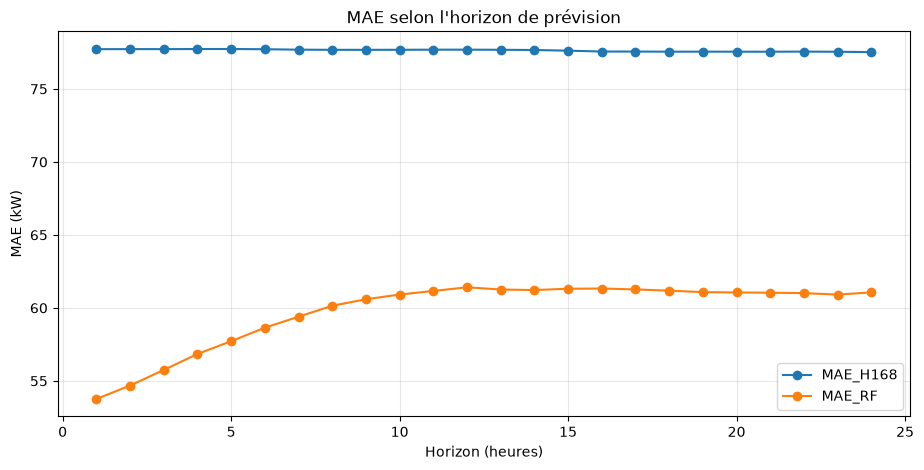

In [362]:
# G.6 — Performances par horizon de prévision

df_horizon_results = df_rf_results.copy()

df_horizon_results["horizon"] = df_val.loc[X_val_weekly.index, "horizon"].to_numpy()

horizon_results = []

for horizon, group in df_horizon_results.groupby("horizon"):
    y_true = group["target_consumption_kw"]

    mae_baseline = mean_absolute_error(y_true, group["target_lag_168h"])

    mae_rf = mean_absolute_error(y_true, group["prediction_rf"])

    horizon_results.append(
        {
            "horizon": horizon,
            "MAE_H168": mae_baseline,
            "MAE_RF": mae_rf,
            "gain_pct": ((mae_baseline - mae_rf) / mae_baseline * 100),
        }
    )

df_rf_by_horizon = pd.DataFrame(horizon_results)

display(df_rf_by_horizon.round(2))

# Visualisation
import matplotlib.pyplot as plt

ax = df_rf_by_horizon.plot(x="horizon", y=["MAE_H168", "MAE_RF"], figsize=(11, 5), marker="o")

ax.set_title("MAE selon l'horizon de prévision")
ax.set_xlabel("Horizon (heures)")
ax.set_ylabel("MAE (kW)")
ax.grid(alpha=0.3)

plt.show()


### G.6 — Bilan de l'analyse par horizon

L'analyse des performances selon l'horizon de prévision montre une augmentation progressive de la MAE de la Random Forest entre H+1 et H+12, suivie d'une stabilisation jusqu'à H+24.

La MAE passe de 53,76 kW à H+1 à 61,06 kW à H+24, tandis que la baseline hebdomadaire reste relativement stable autour de 77,6 kW.

La Random Forest conserve un avantage sur l'ensemble des 24 horizons, avec une réduction de la MAE comprise entre 21,23 % et 30,83 %.

Ces résultats confortent l'intérêt d'un modèle global multi-horizon pour la prévision énergétique à court terme.

Ils soulignent également la nécessité de distinguer la fenêtre d'historique requise pour l'inférence de celle utilisée pour l'entraînement. Une expérimentation complémentaire permettra de mesurer l'influence de la durée de l'historique d'apprentissage sur les performances du modèle.



## H — Évaluation finale sur données indépendantes

### H.1 — Préparation de l'ensemble de test

La Random Forest globale a été entraînée sur les données de 2023 et évaluée sur le premier semestre 2024.

Après avoir retenu cette configuration comme modèle candidat, nous procédons à son évaluation finale sur le second semestre 2024, resté à l'écart des expérimentations précédentes.

L'objectif est de mesurer la capacité du modèle à généraliser ses prévisions à une période chronologique différente.

Pour garantir une comparaison équitable avec les baselines journalière et hebdomadaire, nous identifions les observations disposant des deux références historiques.

Nous conservons également un suivi des observations exclues, notamment lorsque la référence hebdomadaire est indisponible.

Le modèle et ses hyperparamètres restent inchangés pendant cette évaluation.


In [363]:
# H.1 — Préparation de l'ensemble de test

# Référence journalière, construite en F.1
df_test_baselines = df_test.merge(
    daily_reference[["site_id", "target_timestamp", "target_lag_24h"]],
    on=["site_id", "target_timestamp"],
    how="left",
    validate="many_to_one",
)

# Observations compatibles avec le modèle actuel
df_test_weekly = df_test_baselines.dropna(subset=["target_lag_168h"]).copy()

# Observations communes aux deux baselines et au modèle
df_test_common = df_test_baselines.dropna(subset=["target_lag_24h", "target_lag_168h"]).copy()

print("Test total :", len(df_test_baselines))

print("Test avec H-168 :", len(df_test_weekly))

print("Test commun H-24 / H-168 :", len(df_test_common))

print("Test sans H-168 :", df_test_baselines["target_lag_168h"].isna().sum())

print("\nRépartition par type de bâtiment :")

display(df_test_common.groupby("site_type").size().rename("observations").reset_index())

print("\nContrôle des horizons :")
print("Horizons présents :", df_test_common["horizon"].nunique())

Test total : 707943
Test avec H-168 : 680621
Test commun H-24 / H-168 : 654317
Test sans H-168 : 27322

Répartition par type de bâtiment :


,site_type,observations
0,datacenter,93362
1,factory,188880
2,hospital,92956
3,office,185465
4,retail,93654



Contrôle des horizons :
Horizons présents : 24



### H.2 — Évaluation finale sur l'ensemble de test

La Random Forest globale retenue lors des expérimentations est évaluée sur la période indépendante de juillet à décembre 2024.

Nous comparons ses prédictions aux deux modèles de référence, H-24 et H-168, sur un ensemble commun de 654 317 observations.

Les métriques utilisées sont :

- MAE : erreur absolue moyenne, exprimée en kW.
- RMSE : racine de l'erreur quadratique moyenne, exprimée en kW.
- WAPE : erreur absolue rapportée à la consommation totale, exprimée en pourcentage.

Le modèle et ses hyperparamètres restent inchangés. Aucun nouvel entraînement n'est effectué.

Les résultats permettront de mesurer la capacité de généralisation du modèle et de confirmer, ou non, les performances observées en validation.


In [364]:
# H.2 — Évaluation finale sur le test indépendant

# Caractéristiques du sous-ensemble commun
X_test_common = df_test_common[feature_columns]
y_test_common = df_test_common[target_column]

# Prédictions avec le modèle figé
y_pred_test_rf = rf_pipeline.predict(X_test_common)

# Résultats regroupés
df_test_results = df_test_common[
    [
        "site_id",
        "site_type",
        "horizon",
        "target_consumption_kw",
        "target_lag_24h",
        "target_lag_168h",
    ]
].copy()

df_test_results["prediction_rf"] = y_pred_test_rf

# Évaluation des trois méthodes
test_results = []

for name, column in [
    ("Baseline H-24", "target_lag_24h"),
    ("Baseline H-168", "target_lag_168h"),
    ("Random Forest", "prediction_rf"),
]:
    y_true = df_test_results["target_consumption_kw"]
    y_pred = df_test_results[column]

    test_results.append(
        {
            "modele": name,
            "observations": len(y_true),
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
            "WAPE_pct": calculate_wape(y_true, y_pred),
        }
    )

df_final_test_results = pd.DataFrame(test_results)

display(df_final_test_results.round(2))

# Gain de la RF face à la baseline hebdomadaire
mae_h168 = df_final_test_results.loc[
    df_final_test_results["modele"] == "Baseline H-168", "MAE"
].iloc[0]

mae_rf_test = df_final_test_results.loc[
    df_final_test_results["modele"] == "Random Forest", "MAE"
].iloc[0]

gain_test_pct = (mae_h168 - mae_rf_test) / mae_h168 * 100

print(f"\nGain Random Forest vs H-168 : {gain_test_pct:.2f} %")

,modele,observations,MAE,RMSE,WAPE_pct
0,Baseline H-24,654317,118.28,247.03,24.57
1,Baseline H-168,654317,95.99,215.53,19.94
2,Random Forest,654317,74.70,163.29,15.52



Gain Random Forest vs H-168 : 22.18 %



### H.3 — Bilan final et comparaison avec l'expérimentation initiale

L'évaluation finale de la Random Forest globale sur le second semestre 2024 confirme son intérêt pour la prévision énergétique multi-horizon.

Sur 654 317 exemples de test communs aux trois méthodes :

- La baseline journalière H-24 obtient une MAE de 118,28 kW.
- La baseline hebdomadaire H-168 obtient une MAE de 95,99 kW.
- La Random Forest globale obtient une MAE de 74,70 kW, une RMSE de 163,29 kW et un WAPE de 15,52 %.

La Random Forest réduit ainsi la MAE de 22,18 % par rapport à la baseline hebdomadaire.

Ces résultats confirment, sur une période de test chronologiquement indépendante, l'amélioration déjà observée lors de la validation.

La comparaison avec l'expérimentation initiale sur trente jours fait apparaître deux situations distinctes :

| Indicateur | Readings sur 30 jours | Historique 2023–2024 |
|---|---:|---:|
| MAE baseline H-168 | 6,78 kW | 95,99 kW |
| MAE Random Forest | 6,21 kW | 74,70 kW |
| Gain relatif | 8,4 % | 22,18 % |
| Évaluation | Validation | Test indépendant |

Les performances absolues ne sont pas directement comparables, car les deux jeux de données présentent des distributions et des périodes différentes.

Cependant, les deux expérimentations montrent qu'une Random Forest globale peut améliorer les prévisions par rapport à une référence hebdomadaire.

L'expérimentation sur deux années apporte une validation plus robuste de cette approche, tout en révélant une variabilité énergétique plus importante.

Ces résultats ne permettent pas encore de déterminer quelle part de l'amélioration provient de la durée d'entraînement, de la diversité des données ou de leurs caractéristiques statistiques.

Une expérimentation complémentaire sera donc consacrée à l'influence de la durée de l'historique d'entraînement, en conservant un protocole et une période d'évaluation identiques.

Cette dernière étude permettra d'orienter les choix de conservation des données, de constitution des datasets et de réentraînement du futur pipeline MLOps.
